
make_figures figures-1.1 | 2026-10-08T03:31:24.069573+03:30
input   : D:\ptbxl-metadata-audit\outputs\verify\run_20261008-022605\paper_numbers.json
sha256  : e540d16d65d9247669e8488bcc834ea854cdd5bf94f0181f3c9ceb6ff49e524c
sha256 matches the verified paper_numbers.json
verify  : run_20261008-022605 | 370 checks, 0 failed, 0 skipped | all_checks_passed True | paper_final True
versions: {'python': '3.10.20', 'matplotlib': '3.10.9', 'pillow': '12.3.0', 'numpy': '1.26.4', 'os': 'Windows-10-10.0.19045-SP0'}
font    : Times New Roman (C:\Windows\Fonts\times.ttf)

Drawing
Fig. 1 layout (mm): {'left_mm': 27.672, 'right_mm': 2.265, 'bottom_mm': 8.665, 'top_mm': 12.145, 'gap_mm': 5.6, 'panel_h_mm': 21.295, 'axes_w_mm': 55.863, 'longest_ytick_mm': 25.172, 'legend_h_mm': 6.046, 'header_h_mm': 2.6}
Fig. 2 layout (mm): {'left_mm': 14.02, 'right_mm': 0.5, 'bottom_mm': 8.08, 'top_mm': 5.84, 'axes_w_mm': 71.28, 'axes_h_mm': 42.08, 'widest_ytick_mm': 7.938, 'ylabel_mm': 2.582}
A4 preview: [{'figure': '

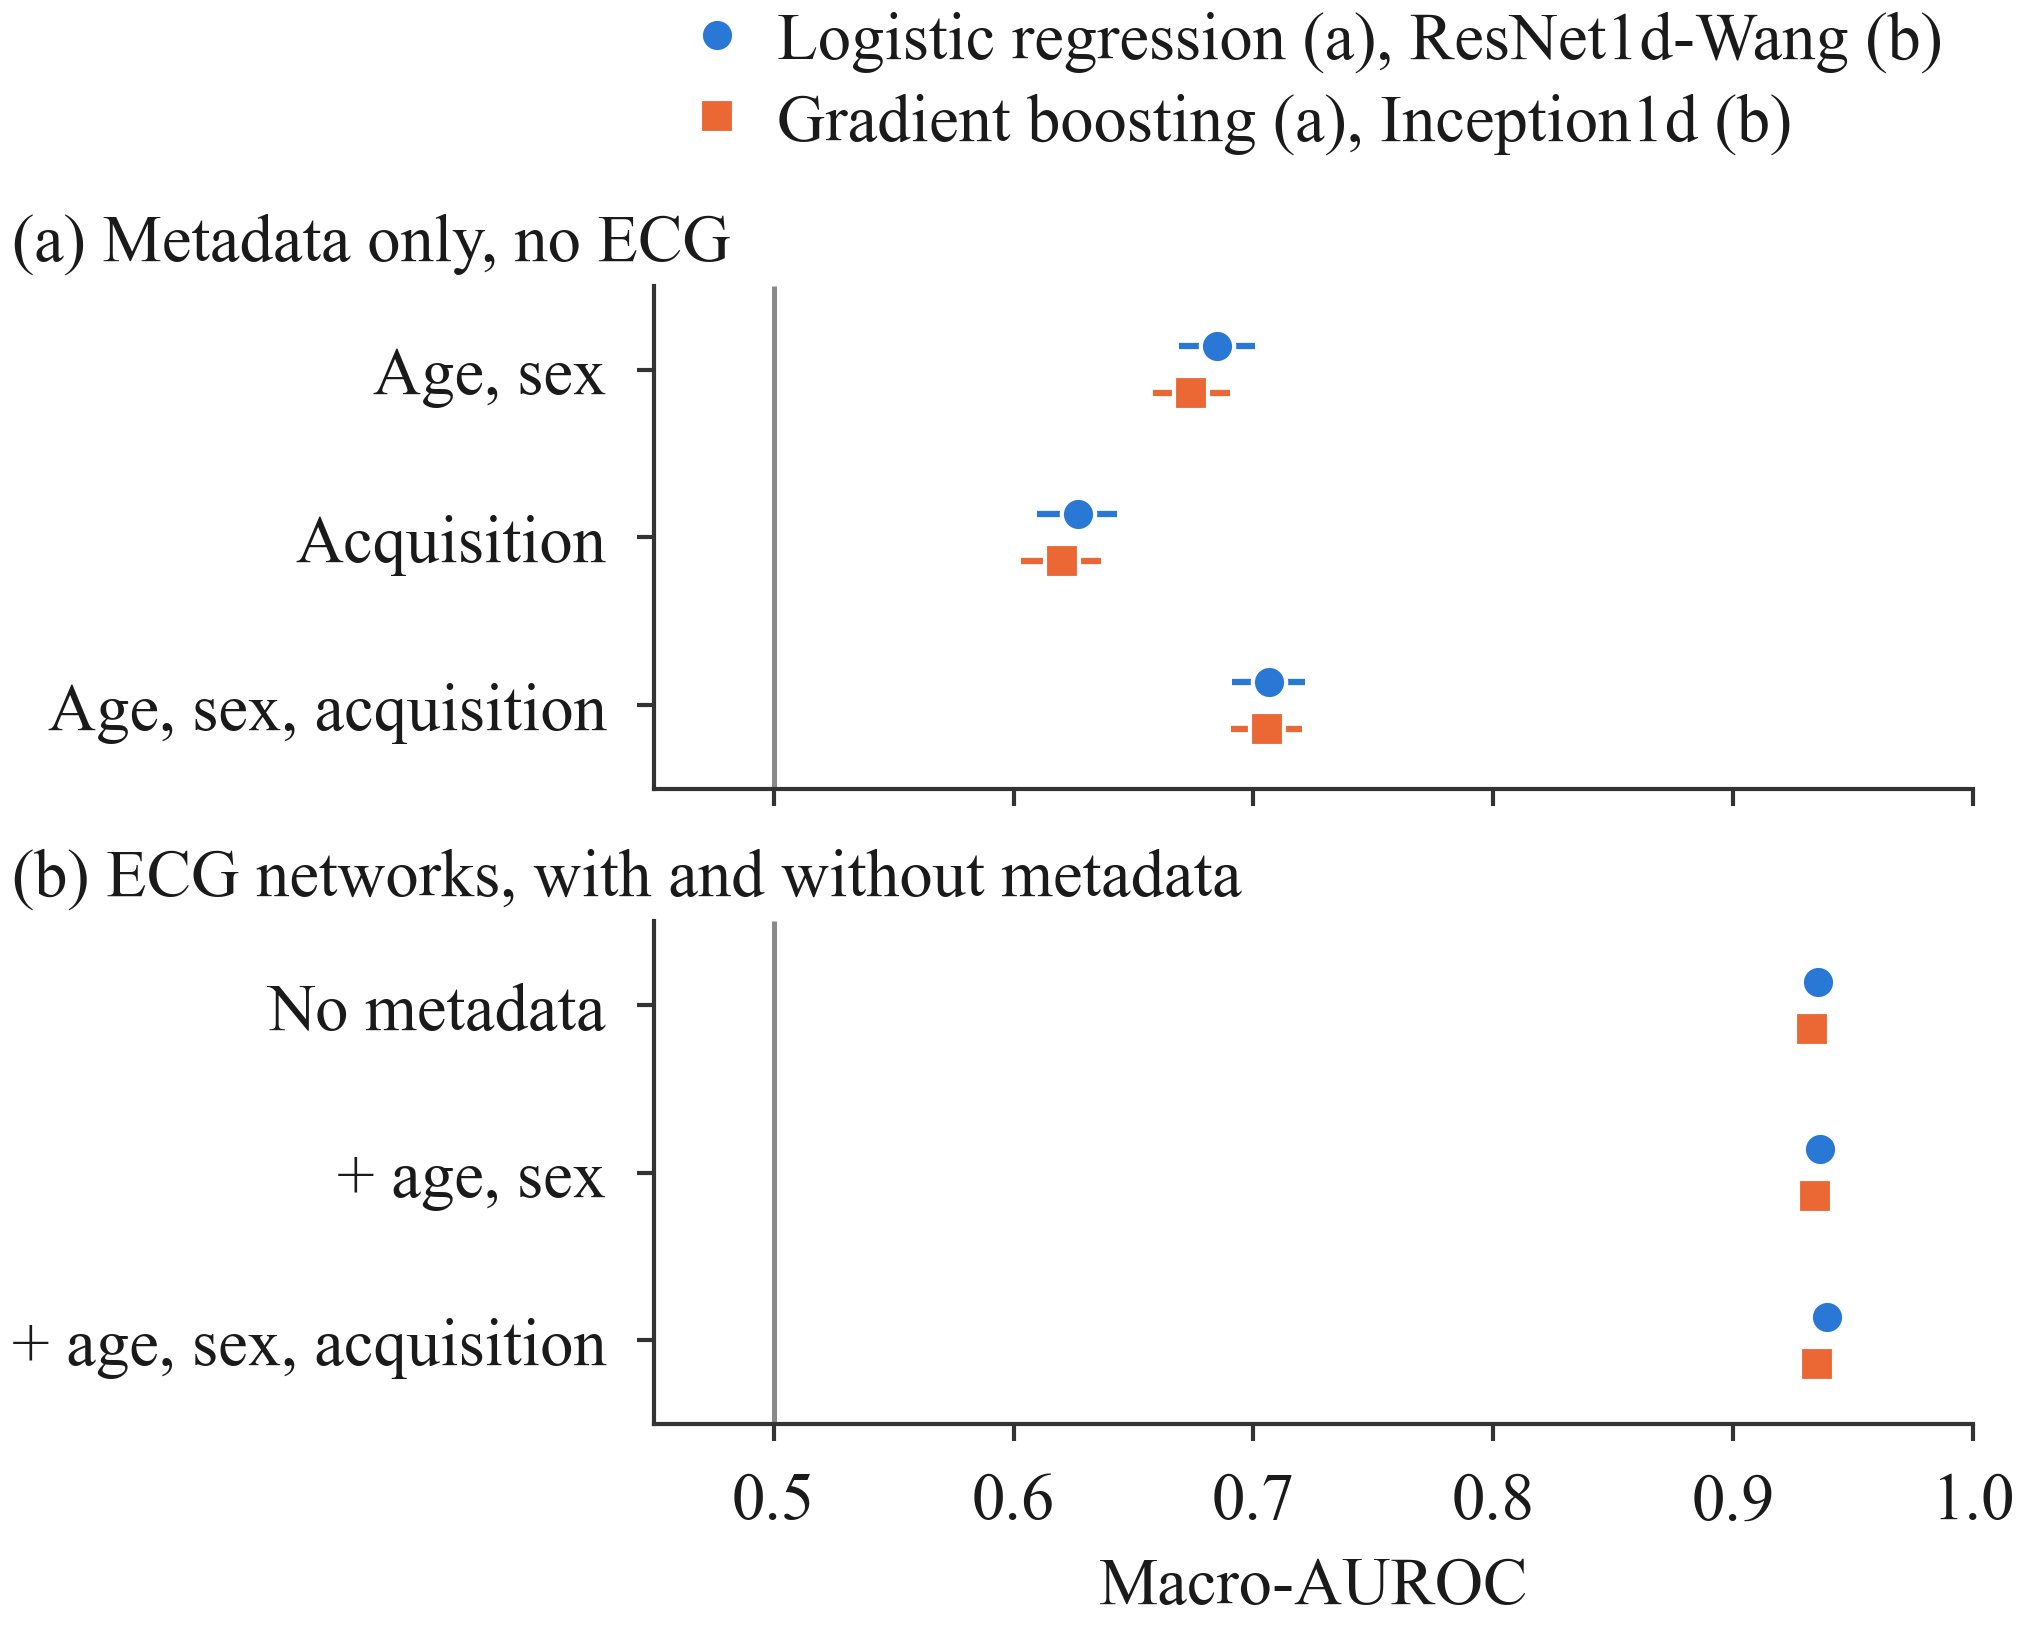

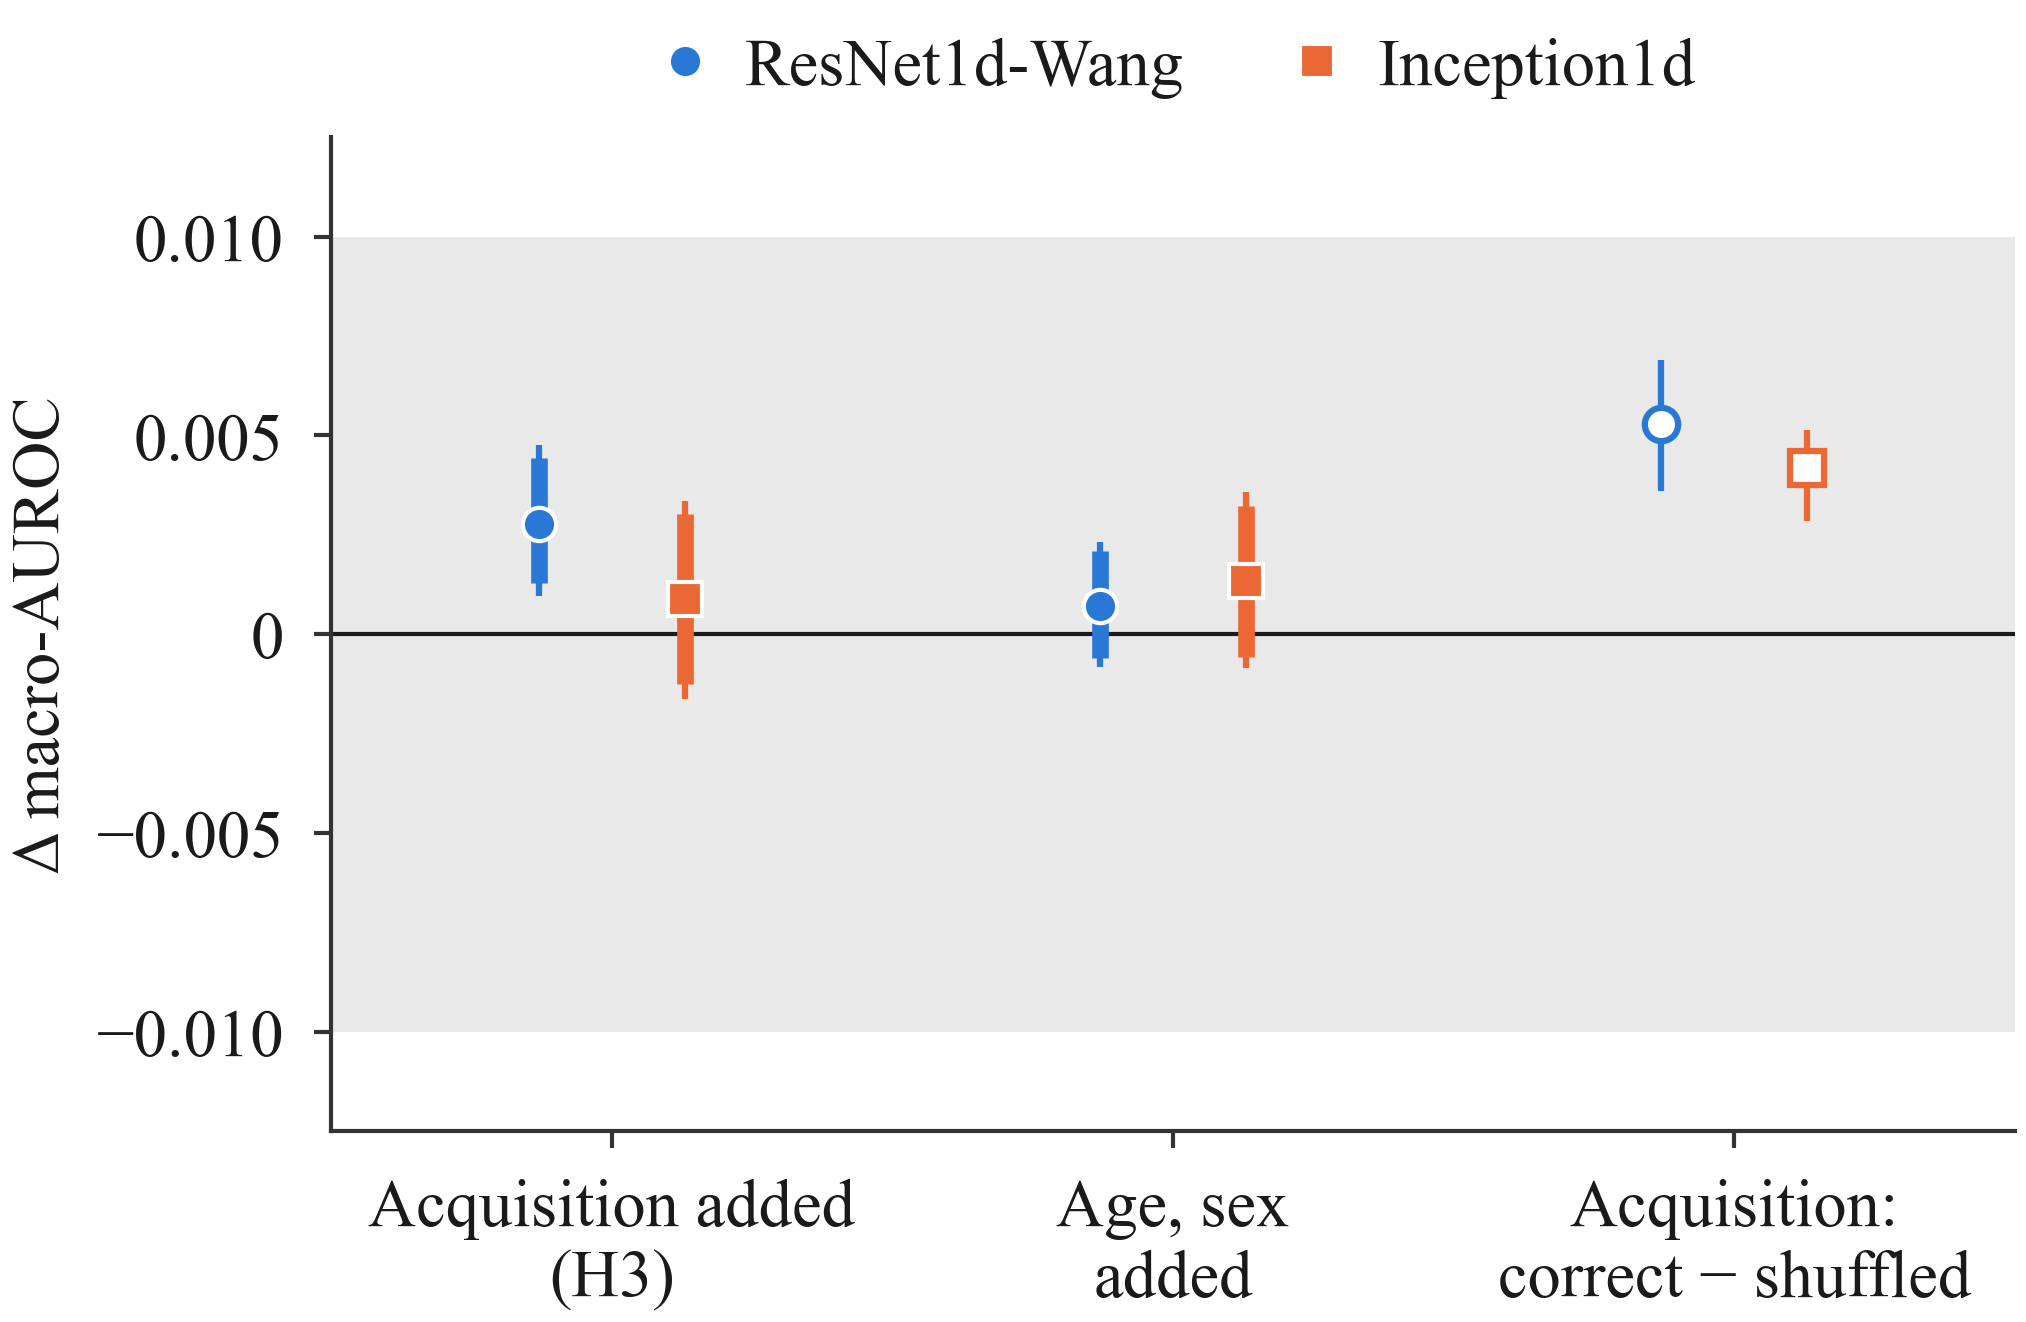

In [1]:
# =====================================================================================
# Project: PTB-XL Metadata Audit  -  make_figures.py: the two paper figures from verified numbers only
# Code version: figures-1.1 (FIGURES_VERSION; 1.1 = core-chat round 2: Fig. 1 single legend above the panels, no
#         gridlines, 69 mm high, new header (b); caption edits; input sha256 pinned; self-checks 5c and 5d)
# Date: 2026-10-08
#
# Input : ONLY paper_numbers.json written by verify.py (default: the most recent ROOT\outputs\verify\run_* folder;
#         --run <folder name or path> selects another). The script refuses to run unless verify.all_checks_passed is
#         true, verify.paper_final is true, schema_version == "1", metadata_only.fold10_posthoc is not null and the
#         file's sha256 == EXPECTED_PN_SHA256 (the verified file of verify run_20261008-022605). No other
#         data source; no number is hard-coded or recomputed (the only constants are the layout / style values of the
#         figure specification, the chance level 0.5 and the axis ranges).
# Output: ROOT\outputs\figures\<verify run id>\ (created new; the run STOPS if it exists; every file exclusive-create):
#         fig1_auroc_levels.{png,tif,pdf}, fig2_delta.{png,tif,pdf}, fig1_auroc_levels_gray.png, fig2_delta_gray.png,
#         figures_preview_A4.pdf, captions.txt, figures_manifest.json (sha256 of every output + paper_numbers.json).
# Run   : python make_figures.py --root D:\ptbxl-metadata-audit [--run run_YYYYmmdd-HHMMSS]
#         or paste the whole file into ONE Jupyter cell (ROOT defaults to D:\ptbxl-metadata-audit).
#         Exit code 1 (script) or a FAIL banner (Jupyter) if any self-check fails.
# Style : one IEEE column (85.8 mm), Times New Roman 8 pt (fallback Liberation Serif -> TeX Gyre Termes ->
#         DejaVu Serif, with a WARN), every axes placed in millimetres, no tight_layout / bbox_inches="tight".
# Self-checks (printed as a report; all must pass): 1 saved size, 2 font size / font / glyphs, 3 text overlap and
#         canvas, 4 legends free of data and reference lines, 5 every plotted value == paper_numbers.json (5b labels,
#         5c CI visibility: Fig. 1 (b) intervals narrower than their markers, (a) intervals visible; 5d no two data
#         markers overlap), 6 outputs exist and are recorded in figures_manifest.json.
# Dependencies: matplotlib, numpy, Pillow (and the standard library). Environment of the paper: Python 3.10.20,
#         matplotlib 3.10.9, Pillow 12.3.0, numpy 1.26.4 (other versions: WARN).
# =====================================================================================

import os, sys, io, json, glob, hashlib, argparse, platform
from datetime import datetime
import numpy as np
import matplotlib
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FixedLocator, FixedFormatter
from matplotlib import font_manager
from matplotlib.transforms import Bbox
from PIL import Image
from fontTools.ttLib import TTFont            # shipped with matplotlib (glyph-coverage check)

FIGURES_VERSION = "figures-1.1"
EXPECTED_PN_SHA256 = "e540d16d65d9247669e8488bcc834ea854cdd5bf94f0181f3c9ceb6ff49e524c"
DEFAULT_ROOT = r"D:\ptbxl-metadata-audit"
EXPECTED_VERSIONS = {"python": "3.10.20", "matplotlib": "3.10.9", "pillow": "12.3.0", "numpy": "1.26.4"}

# ------------------------------------- specification constants (layout and style only) -------------------------------
MM = 1.0 / 25.4                                   # inches per mm
DPI = 600
COL_W_MM = 85.8                                   # one column: A4, 16.0 mm side margins, 6.35 mm column gap
FIG1_H_MM, FIG2_H_MM = 69.0, 56.0
SIZE_TOL_MM = 0.1
FONT_CANDIDATES = ["Times New Roman", "Liberation Serif", "TeX Gyre Termes", "DejaVu Serif"]
FONT_SIZE = 8.0
INK, SPINE, BAND, REFLINE = "#1a1a1a", "#333333", "#e9e9e9", "#8a8a8a"
PRIMARY, ROBUST = "#2a78d6", "#eb6834"            # primary series (filled circle), robustness series (filled square)
SPINE_LW, TICK_LEN, TICK_W = 0.5, 2.0, 0.5         # pt
MARKER_SIZE, MARKER_EDGE_W = 4.0, 0.5             # pt
CI95_LW, CI90_LW, CHANCE_LW, ZERO_LW = 0.75, 2.0, 0.6, 0.5
HOLLOW_EDGE_W = 0.75
OUTER_MM = 0.5                                    # gap between the outermost text and the canvas edge
LABEL_TO_SPINE_MM = 2.0                           # tick (2 pt) + pad; longest y tick label + 2.5 mm = left margin
TICK_PAD_PT = LABEL_TO_SPINE_MM * MM * 72.0 - TICK_LEN
OVERLAP_TOL_PT = 0.5
SAMPLE_STEP_MM = 0.5
ROW_OFFSET = 0.14
FIG1_XLIM, FIG1_XTICKS, FIG1_XTICKLABELS = (0.45, 1.00), [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], \
    ["0.5", "0.6", "0.7", "0.8", "0.9", "1.0"]
CHANCE = 0.5
FIG2_XLIM, FIG2_YLIM = (-0.5, 2.5), (-0.0125, 0.0125)
FIG2_YTICKS, FIG2_YTICKLABELS = [-0.010, -0.005, 0.0, 0.005, 0.010], ["\u22120.010", "\u22120.005", "0", "0.005", "0.010"]
FIG2_GROUP_LABELS = ["Acquisition added\n(H3)", "Age, sex\nadded", "Acquisition:\ncorrect \u2212 shuffled"]
FIG2_DX = 0.13
SPEC_SESOI = 0.01                                 # the band of Fig. 2 is h3.sesoi_h3, asserted == this specification
ROWS_A = [("B1_physio", "Age, sex"), ("B2_acquisition", "Acquisition"),
          ("B3_physio_plus_acquisition", "Age, sex, acquisition")]          # top to bottom
ROWS_B = [("signal_only", "No metadata"), ("signal_plus_physio", "+ age, sex"),
          ("signal_plus_all", "+ age, sex, acquisition")]
LEARNERS = [("LogisticRegression", "Logistic regression", PRIMARY, "o", +1),
            ("HistGradientBoosting", "Gradient boosting", ROBUST, "s", -1)]
ARCHS = [("resnet1d_wang", "ResNet1d-Wang", PRIMARY, "o", +1), ("inception1d", "Inception1d", ROBUST, "s", -1)]
HEADER_A, HEADER_B, XLABEL_1, YLABEL_2 = "(a) Metadata only, no ECG", "(b) ECG networks, with and without metadata", \
    "Macro-AUROC", \
    "\u0394 macro-AUROC"
FIG1_LEGEND = [("", "Logistic regression (a), ResNet1d-Wang (b)", PRIMARY, "o", +1),
               ("", "Gradient boosting (a), Inception1d (b)", ROBUST, "s", -1)]
FIG1_LEGEND_TO_HEADER_MM, FIG1_HEADER_B_GAP_MM = 2.0, 3.0
A4_W_MM, A4_H_MM, A4_SIDE_MM, A4_GAP_MM, A4_TOP_MM, A4_BOTTOM_MM = 210.0, 297.0, 16.0, 6.35, 19.0, 25.0
CAPTION_GAP_MM, BODY_GAP_MM, CAPTION_LINE_SPACING = 2.0, 4.0, 1.2
CAPTIONS = {
    "fig1": ("Fig. 1. Macro-AUROC over the five diagnostic superclasses on the test fold (fold 10). (a) Metadata-only "
             "models trained on folds 1\u20139 (post hoc); gradient boosting values and intervals are means over three "
             "seeds. Acquisition metadata: recording device, site and nurse. (b) ECG networks (three-seed ensembles) "
             "without metadata, with age and sex, and with age, sex and acquisition metadata. Horizontal lines: 95% "
             "patient-level bootstrap intervals (2,000 resamples); in (b) they are narrower than the markers. Vertical "
             "line: chance level."),
    "fig2": ("Fig. 2. Change in test-fold macro-AUROC. Left: adding acquisition metadata to an ECG network that already "
             "receives age and sex (pre-registered H3; ResNet1d-Wang primary, Inception1d robustness). Middle: adding "
             "age and sex to the ECG-only network (exploratory). Right: correct minus shuffled acquisition metadata, "
             "mean (hollow marker) and range over 20 shuffles (exploratory). Thick and thin bars: 90% and 95% "
             "patient-level bootstrap intervals (2,000 resamples). Shaded band: \u00b10.01, the pre-registered smallest "
             "effect size of interest for H3."),
}


def in_ipython():
    try:
        get_ipython  # noqa: F821
        return True
    except NameError:
        return False


IN_IPYTHON = in_ipython()


def hdr(t):
    print("\n" + "=" * 100)
    print(t)
    print("=" * 100)


def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()


def sha256_of(path):
    with open(path, "rb") as f:
        return sha256_bytes(f.read())


def write_once(path, data):
    """Exclusive create; never overwrites. Returns the sha256 of the bytes on disk."""
    with open(path, "xb") as f:
        f.write(data)
    got = sha256_of(path)
    assert got == sha256_bytes(data), "write verification failed for " + path
    return got


def px2mm(v):
    return v / DPI * 25.4


def mm2px(v):
    return v * MM * DPI


# =====================================================================================
# 0. Arguments, input, refusals
# =====================================================================================
hdr("make_figures {} | {}".format(FIGURES_VERSION, datetime.now().astimezone().isoformat()))
_ap = argparse.ArgumentParser(add_help=False)
_ap.add_argument("--root", default=DEFAULT_ROOT)
_ap.add_argument("--run", default=None)
ARGS = _ap.parse_known_args()[0]
ROOT = ARGS.root
VERIFY_DIR = os.path.join(ROOT, "outputs", "verify")
if ARGS.run:
    RUN_DIR = ARGS.run if os.path.isdir(ARGS.run) else os.path.join(VERIFY_DIR, ARGS.run)
else:
    _runs = sorted(d for d in glob.glob(os.path.join(VERIFY_DIR, "run_*")) if os.path.isdir(d))
    if not _runs:
        raise RuntimeError("STOP: no verify run folder in {}".format(VERIFY_DIR))
    RUN_DIR = _runs[-1]
PN_PATH = os.path.join(RUN_DIR, "paper_numbers.json")
if not os.path.isfile(PN_PATH):
    raise RuntimeError("STOP: {} not found (pass --run to choose a verify run explicitly)".format(PN_PATH))
with open(PN_PATH, "rb") as _f:
    PN_BYTES = _f.read()
PN_SHA256 = sha256_bytes(PN_BYTES)
PN = json.loads(PN_BYTES.decode("utf-8"))
print("input   : {}\nsha256  : {}".format(PN_PATH, PN_SHA256))
_v = PN.get("verify", {})
_refuse = []
if PN.get("schema_version") != "1":
    _refuse.append("schema_version is {!r}, not '1'".format(PN.get("schema_version")))
if _v.get("all_checks_passed") is not True:
    _refuse.append("verify.all_checks_passed is not true")
if _v.get("paper_final") is not True:
    _refuse.append("verify.paper_final is not true")
if PN.get("metadata_only", {}).get("fold10_posthoc") is None:
    _refuse.append("metadata_only.fold10_posthoc is null")
if PN_SHA256 != EXPECTED_PN_SHA256:
    _refuse.append("sha256 {} != EXPECTED_PN_SHA256 {} (not the verified paper_numbers.json)".format(
        PN_SHA256, EXPECTED_PN_SHA256))
if _v.get("run_id") != os.path.basename(os.path.normpath(RUN_DIR)):
    _refuse.append("verify.run_id {!r} != run folder name {!r}".format(_v.get("run_id"), os.path.basename(RUN_DIR)))
if _refuse:
    raise RuntimeError("REFUSED: " + "; ".join(_refuse))
RUN_ID = _v["run_id"]
print("sha256 matches the verified paper_numbers.json")
print("verify  : {} | {} checks, {} failed, {} skipped | all_checks_passed {} | paper_final {}".format(
    RUN_ID, _v.get("n_checks"), _v.get("n_failed"), _v.get("n_skipped"), _v["all_checks_passed"], _v["paper_final"]))
OUT_DIR = os.path.join(ROOT, "outputs", "figures", RUN_ID)
if os.path.exists(OUT_DIR):
    raise RuntimeError("STOP: {} already exists - an output folder is never overwritten".format(OUT_DIR))

# --- versions (WARN only) ---
VERSIONS = {"python": sys.version.split()[0], "matplotlib": matplotlib.__version__,
            "pillow": Image.__version__ if hasattr(Image, "__version__") else __import__("PIL").__version__,
            "numpy": np.__version__, "os": platform.platform()}
WARNINGS = []
for _k, _e in EXPECTED_VERSIONS.items():
    if VERSIONS[_k] != _e:
        WARNINGS.append("{} {} != {} (renderer metrics may differ; the self-checks decide)".format(_k, VERSIONS[_k], _e))
print("versions: {}".format(VERSIONS))

# --- font ---
FONT_NAME, FONT_PATH = None, None
for _name in FONT_CANDIDATES:
    try:
        _p = font_manager.findfont(font_manager.FontProperties(family=_name, weight="normal", style="normal"),
                                   fallback_to_default=False)
    except ValueError:
        continue
    if font_manager.FontProperties(fname=_p).get_name() == _name:
        FONT_NAME, FONT_PATH = _name, _p
        break
if FONT_NAME is None:
    raise RuntimeError("STOP: none of the fonts {} is installed".format(FONT_CANDIDATES))
print("font    : {} ({})".format(FONT_NAME, FONT_PATH))
if FONT_NAME != FONT_CANDIDATES[0]:
    WARNINGS.append("font fallback: {} is used instead of Times New Roman".format(FONT_NAME))
for _w in WARNINGS:
    print("[WARN] " + _w)

RC = {"font.family": [FONT_NAME], "font.size": FONT_SIZE, "font.weight": "normal", "font.style": "normal",
      "text.color": INK, "pdf.fonttype": 42, "ps.fonttype": 42, "text.usetex": False, "axes.unicode_minus": False,
      "axes.titlesize": FONT_SIZE, "axes.labelsize": FONT_SIZE, "xtick.labelsize": FONT_SIZE,
      "ytick.labelsize": FONT_SIZE, "legend.fontsize": FONT_SIZE, "legend.title_fontsize": FONT_SIZE,
      "lines.solid_capstyle": "butt", "lines.dash_capstyle": "butt", "savefig.facecolor": "white",
      "figure.facecolor": "white", "axes.facecolor": "white", "pdf.compression": 6, "svg.fonttype": "none"}


# =====================================================================================
# 1. Drawing helpers
# =====================================================================================
def new_figure(w_mm, h_mm):
    fig = Figure(figsize=(w_mm * MM, h_mm * MM), dpi=DPI)
    FigureCanvasAgg(fig)
    return fig


def renderer_of(fig):
    fig.canvas.draw()
    return fig.canvas.get_renderer()


def style_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_linewidth(SPINE_LW)
        ax.spines[side].set_color(SPINE)
    ax.tick_params(axis="both", which="both", direction="out", length=TICK_LEN, width=TICK_W, color=SPINE,
                   labelcolor=INK, labelsize=FONT_SIZE, pad=TICK_PAD_PT, top=False, right=False)
    ax.tick_params(axis="both", which="minor", length=0)
    ax.set_title("")


def marker_kw(color, marker, hollow=False):
    if hollow:
        return dict(marker=marker, markersize=MARKER_SIZE, markerfacecolor="white", markeredgecolor=color,
                    markeredgewidth=HOLLOW_EDGE_W, linestyle="none")
    return dict(marker=marker, markersize=MARKER_SIZE, markerfacecolor=color, markeredgecolor="white",
                markeredgewidth=MARKER_EDGE_W, linestyle="none")


def legend_handles(series):
    return [Line2D([], [], label=label, **marker_kw(color, marker)) for _, label, color, marker, _ in series]


# =====================================================================================
# 2. Fig. 1 - test-fold macro-AUROC, metadata-only versus ECG
# =====================================================================================
def build_fig1(pn):
    fig = new_figure(COL_W_MM, FIG1_H_MM)
    meta = pn["metadata_only"]["fold10_posthoc"]
    ecg = pn["ecg_fold10"]
    ax_b = fig.add_axes([0.5, 0.1, 0.4, 0.3])
    ax_a = fig.add_axes([0.5, 0.5, 0.4, 0.3], sharex=ax_b)
    panels = ((ax_a, "a", ROWS_A, LEARNERS, lambda key, ser: meta[key][ser], "ci95"),
              (ax_b, "b", ROWS_B, ARCHS, lambda key, ser: ecg[ser][key], "ci95_descriptive"))
    for ax, tag, rows, series, get, ci_key in panels:
        style_axes(ax)
        ax.set_xlim(*FIG1_XLIM)
        ax.set_ylim(-0.5, len(rows) - 0.5)
        ax.xaxis.set_major_locator(FixedLocator(FIG1_XTICKS))
        ax.xaxis.set_major_formatter(FixedFormatter(FIG1_XTICKLABELS))
        ys = [len(rows) - 1 - i for i in range(len(rows))]
        ax.yaxis.set_major_locator(FixedLocator(ys))
        ax.yaxis.set_major_formatter(FixedFormatter([lab for _, lab in rows]))
        ax.axvline(CHANCE, color=REFLINE, linewidth=CHANCE_LW, zorder=1, gid="fig1/{}/chance".format(tag))
        for (key, _), y in zip(rows, ys):
            for ser, _, color, marker, sign in series:
                d = get(key, ser)
                yy = y + sign * ROW_OFFSET
                lo, hi = d[ci_key]
                ax.add_line(Line2D([lo, hi], [yy, yy], color=color, linewidth=CI95_LW, solid_capstyle="butt",
                                   zorder=3, gid="fig1/{}/{}/{}/ci95".format(tag, key, ser)))
                ax.add_line(Line2D([d["auroc"]], [yy], zorder=4, gid="fig1/{}/{}/{}/point".format(tag, key, ser),
                                   **marker_kw(color, marker)))
    ax_a.tick_params(axis="x", labelbottom=False)
    leg = fig.legend(handles=legend_handles(FIG1_LEGEND), loc="upper center", bbox_to_anchor=(0.5, 1.0),
                     bbox_transform=fig.transFigure, ncol=1, frameon=False, borderpad=0, borderaxespad=0,
                     handlelength=1.0, handletextpad=0.4, labelspacing=0.3)
    hdr_a = fig.text(0, 0, HEADER_A, ha="left", va="bottom")
    hdr_b = fig.text(0, 0, HEADER_B, ha="left", va="bottom")
    xlab = fig.text(0, 0, XLABEL_1, ha="center", va="bottom")
    # ---- layout in millimetres (measured with the renderer) ----
    r = renderer_of(fig)
    w_lab = max(px2mm(t.get_window_extent(r).width) for ax in (ax_a, ax_b) for t in ax.get_yticklabels())
    h_tick = max(px2mm(t.get_window_extent(r).height) for t in ax_b.get_xticklabels())
    w_last = px2mm(ax_b.get_xticklabels()[-1].get_window_extent(r).width)
    h_xl = px2mm(xlab.get_window_extent(r).height)
    h_hdr = max(px2mm(hdr_a.get_window_extent(r).height), px2mm(hdr_b.get_window_extent(r).height))
    h_leg = px2mm(leg.get_window_extent(r).height)
    left = OUTER_MM + w_lab + LABEL_TO_SPINE_MM
    right = w_last / 2.0 + OUTER_MM
    bottom = OUTER_MM + h_xl + 1.0 + h_tick + LABEL_TO_SPINE_MM
    top = OUTER_MM + h_leg + FIG1_LEGEND_TO_HEADER_MM + h_hdr + 1.0
    gap = h_hdr + FIG1_HEADER_B_GAP_MM
    panel_h = (FIG1_H_MM - bottom - top - gap) / 2.0
    axw = COL_W_MM - left - right
    W, H = COL_W_MM, FIG1_H_MM
    ax_b.set_position([left / W, bottom / H, axw / W, panel_h / H])
    ax_a.set_position([left / W, (bottom + panel_h + gap) / H, axw / W, panel_h / H])
    hdr_a.set_position((OUTER_MM / W, (bottom + 2 * panel_h + gap + 0.5) / H))
    hdr_b.set_position((OUTER_MM / W, (bottom + panel_h + 0.5) / H))
    xlab.set_position(((left + axw / 2.0) / W, OUTER_MM / H))
    xlab.set_ha("center")
    xlab.set_multialignment("center")
    leg.set_bbox_to_anchor(((left + axw / 2.0) / W, (H - OUTER_MM) / H), transform=fig.transFigure)
    layout = {"left_mm": left, "right_mm": right, "bottom_mm": bottom, "top_mm": top, "gap_mm": gap,
              "panel_h_mm": panel_h, "axes_w_mm": axw, "longest_ytick_mm": w_lab, "legend_h_mm": h_leg,
              "header_h_mm": h_hdr}
    return fig, layout


# =====================================================================================
# 3. Fig. 2 - changes in test-fold macro-AUROC
# =====================================================================================
def build_fig2(pn):
    fig = new_figure(COL_W_MM, FIG2_H_MM)
    h3, ex = pn["h3"], pn["exploratory"]
    sesoi = h3["sesoi_h3"]
    ax = fig.add_axes([0.3, 0.2, 0.6, 0.6])
    style_axes(ax)
    ax.set_xlim(*FIG2_XLIM)
    ax.set_ylim(*FIG2_YLIM)
    ax.xaxis.set_major_locator(FixedLocator([0, 1, 2]))
    ax.xaxis.set_major_formatter(FixedFormatter(FIG2_GROUP_LABELS))
    ax.yaxis.set_major_locator(FixedLocator(FIG2_YTICKS))
    ax.yaxis.set_major_formatter(FixedFormatter(FIG2_YTICKLABELS))
    for t in ax.get_xticklabels():
        t.set_multialignment("center")
    ax.axhspan(-sesoi, sesoi, facecolor=BAND, edgecolor="none", linewidth=0, zorder=0, gid="fig2/band")
    ax.axhline(0.0, color=INK, linewidth=ZERO_LW, zorder=1, gid="fig2/zero")
    groups = [("h3", {"resnet1d_wang": h3["primary"], "inception1d": h3["robustness"]}),
              ("e1", ex["E1_physio_minus_signal_only"])]
    for gx, (tag, data) in enumerate(groups):
        for arch, _, color, marker, sign in ARCHS:
            d = data[arch]
            x = gx - sign * FIG2_DX                  # primary (sign +1) at x - 0.13, robustness at x + 0.13
            ax.add_line(Line2D([x, x], list(d["ci95"]), color=color, linewidth=CI95_LW, solid_capstyle="butt",
                               zorder=3, gid="fig2/{}/{}/ci95".format(tag, arch)))
            ax.add_line(Line2D([x, x], list(d["ci90"]), color=color, linewidth=CI90_LW, solid_capstyle="butt",
                               zorder=3.5, gid="fig2/{}/{}/ci90".format(tag, arch)))
            ax.add_line(Line2D([x], [d["point_delta"]], zorder=4, gid="fig2/{}/{}/point".format(tag, arch),
                               **marker_kw(color, marker)))
    for arch, _, color, marker, sign in ARCHS:
        d = ex["E3_acquisition_permutation"][arch]
        x = 2 - sign * FIG2_DX
        ax.add_line(Line2D([x, x], [d["drop_min"], d["drop_max"]], color=color, linewidth=CI95_LW,
                           solid_capstyle="butt", zorder=3, gid="fig2/e3/{}/range".format(arch)))
        ax.add_line(Line2D([x], [d["drop_mean"]], zorder=4, gid="fig2/e3/{}/mean".format(arch),
                           **marker_kw(color, marker, hollow=True)))
    leg = ax.legend(handles=legend_handles(ARCHS), loc="lower center", bbox_to_anchor=(0.5, 0.9),
                    bbox_transform=fig.transFigure, ncol=2, frameon=False, borderaxespad=0.0, handlelength=1.0,
                    handletextpad=0.4, columnspacing=1.5, borderpad=0.4)
    ylab = fig.text(0, 0, YLABEL_2, rotation=90, ha="left", va="center")
    # ---- layout ----
    r = renderer_of(fig)
    h_yl = px2mm(ylab.get_window_extent(r).width)
    w_yt = max(px2mm(t.get_window_extent(r).width) for t in ax.get_yticklabels())
    xt = ax.get_xticklabels()
    h_xt = max(px2mm(t.get_window_extent(r).height) for t in xt)
    hw_last = px2mm(xt[-1].get_window_extent(r).width) / 2.0
    h_leg = px2mm(leg.get_window_extent(r).height)
    left = OUTER_MM + h_yl + 1.0 + w_yt + LABEL_TO_SPINE_MM
    bottom = OUTER_MM + h_xt + LABEL_TO_SPINE_MM
    top = h_leg + 1.0
    span = FIG2_XLIM[1] - FIG2_XLIM[0]
    frac_last = (2 - FIG2_XLIM[0]) / span
    axw = min(COL_W_MM - left - OUTER_MM, (COL_W_MM - OUTER_MM - left - hw_last) / frac_last)
    axh = FIG2_H_MM - bottom - top
    W, H = COL_W_MM, FIG2_H_MM
    ax.set_position([left / W, bottom / H, axw / W, axh / H])
    ylab.set_position((OUTER_MM / W, (bottom + axh / 2.0) / H))
    leg.set_bbox_to_anchor(((left + axw / 2.0) / W, (bottom + axh + 0.5) / H), transform=fig.transFigure)
    layout = {"left_mm": left, "right_mm": COL_W_MM - left - axw, "bottom_mm": bottom, "top_mm": top,
              "axes_w_mm": axw, "axes_h_mm": axh, "widest_ytick_mm": w_yt, "ylabel_mm": h_yl}
    return fig, layout


# =====================================================================================
# 4. Rendering and saving (PNG / TIFF RGB 600 dpi, PDF TrueType)
# =====================================================================================
def render_rgb(fig):
    fig.canvas.draw()
    buf = np.asarray(fig.canvas.buffer_rgba())
    assert (buf[:, :, 3] == 255).all(), "the rendered figure has transparent pixels"
    return Image.fromarray(buf[:, :, :3].copy(), mode="RGB")


def png_bytes(img, mode=None):
    b = io.BytesIO()
    (img.convert(mode) if mode else img).save(b, format="PNG", dpi=(DPI, DPI))
    return b.getvalue()


def tif_bytes(img):
    b = io.BytesIO()
    img.save(b, format="TIFF", compression="tiff_lzw", dpi=(DPI, DPI))
    return b.getvalue()


def pdf_bytes(fig):
    b = io.BytesIO()
    fig.savefig(b, format="pdf", dpi=DPI, facecolor="white", metadata={"Creator": FIGURES_VERSION,
                                                                       "CreationDate": None})
    return b.getvalue()


# =====================================================================================
# 5. Self-checks
# =====================================================================================
CHECKS = []


def check(cid, description, ok, detail):
    CHECKS.append({"id": cid, "description": description, "status": "PASS" if ok else "FAIL", "detail": detail})


def visible_texts(fig):
    out = [t for t in fig.texts if t.get_visible() and t.get_text().strip()]
    for ax in fig.axes:
        for t in ax.xaxis.get_majorticklabels() + ax.yaxis.get_majorticklabels():
            if t.get_visible() and t.get_text().strip():
                out.append(t)
        for t in (ax.xaxis.label, ax.yaxis.label, ax.title, ax._left_title, ax._right_title,
                  ax.xaxis.get_offset_text(), ax.yaxis.get_offset_text()):
            if t.get_visible() and t.get_text().strip():
                out.append(t)
        leg = ax.get_legend()
        if leg is not None:
            out += [t for t in leg.get_texts() if t.get_visible() and t.get_text().strip()]
    for leg in fig.legends:
        out += [t for t in leg.get_texts() if t.get_visible() and t.get_text().strip()]
    return out


FONT_CMAP = set(TTFont(FONT_PATH, fontNumber=0).getBestCmap().keys())


def check_size(name, png_b, tif_b, pdf_b, w_mm, h_mm):
    im = Image.open(io.BytesIO(png_b))
    wp, hp = px2mm(im.size[0]), px2mm(im.size[1])
    ti = Image.open(io.BytesIO(tif_b))
    wt, ht = px2mm(ti.size[0]), px2mm(ti.size[1])
    import re
    m = re.search(rb"/MediaBox\s*\[\s*0\s+0\s+([\d.]+)\s+([\d.]+)\s*\]", pdf_b)
    wpd, hpd = (float(m.group(1)) / 72 * 25.4, float(m.group(2)) / 72 * 25.4) if m else (None, None)
    ok = all(abs(a - b) <= SIZE_TOL_MM for a, b in ((wp, w_mm), (hp, h_mm), (wt, w_mm), (ht, h_mm))) and \
        m is not None and abs(wpd - w_mm) <= SIZE_TOL_MM and abs(hpd - h_mm) <= SIZE_TOL_MM and \
        ti.info.get("compression") == "tiff_lzw" and im.mode == "RGB" and ti.mode == "RGB"
    fonts_ok = b"/FontFile2" in pdf_b and b"/FontFile3" not in pdf_b and b"/Subtype /Type1" not in pdf_b \
        and b"/Subtype /Type3" not in pdf_b
    check("1_size_" + name, "{}: saved size == {} x {} mm (+/-{} mm) from PNG pixels at {} dpi (also TIFF pixels, PDF "
          "MediaBox); RGB; TIFF LZW; PDF fonts embedded TrueType".format(name, w_mm, h_mm, SIZE_TOL_MM, DPI),
          ok and fonts_ok, "PNG {} x {} px = {:.3f} x {:.3f} mm | TIFF {:.3f} x {:.3f} mm ({}) | PDF {} x {} mm | "
          "PDF TrueType embedded {}".format(im.size[0], im.size[1], wp, hp, wt, ht, ti.info.get("compression"),
                                           None if wpd is None else round(wpd, 3), None if hpd is None else round(hpd, 3),
                                           fonts_ok))


def check_fonts(name, fig):
    bad = []
    texts = visible_texts(fig)
    for t in texts:
        fp = t.get_fontproperties()
        path = font_manager.findfont(fp, fallback_to_default=False)
        missing = sorted({hex(ord(c)) for c in t.get_text() if c not in "\n" and ord(c) not in FONT_CMAP})
        if fp.get_size_in_points() != FONT_SIZE or os.path.normcase(path) != os.path.normcase(FONT_PATH) or \
                fp.get_weight() not in ("normal", 400) or fp.get_style() != "normal" or missing or \
                "$" in t.get_text():
            bad.append({"text": t.get_text(), "size": fp.get_size_in_points(), "font": path, "weight": fp.get_weight(),
                        "style": fp.get_style(), "missing_glyphs": missing})
    check("2_text_" + name, "{}: every visible text is {} pt, regular, upright, in the resolved font ({}), every glyph "
          "present in that font, no mathtext".format(name, FONT_SIZE, FONT_NAME), not bad,
          "{} texts checked; violations: {}".format(len(texts), bad))


def check_overlap(name, fig):
    r = renderer_of(fig)
    tol = OVERLAP_TOL_PT / 72.0 * DPI
    W, H = fig.bbox.width, fig.bbox.height
    items = [(t.get_text().replace("\n", " / "), t.get_window_extent(r)) for t in visible_texts(fig)]
    overl, outside = [], []
    for i in range(len(items)):
        a = items[i][1]
        if a.x0 < 0 or a.y0 < 0 or a.x1 > W or a.y1 > H:
            outside.append(items[i][0])
        for j in range(i + 1, len(items)):
            b = items[j][1]
            ix = min(a.x1, b.x1) - max(a.x0, b.x0)
            iy = min(a.y1, b.y1) - max(a.y0, b.y0)
            if ix > tol and iy > tol:
                overl.append((items[i][0], items[j][0], round(px2mm(ix), 3), round(px2mm(iy), 3)))
    check("3_overlap_" + name, "{}: no two text boxes overlap (renderer extents, {} pt tolerance); every text box "
          "inside the canvas".format(name, OVERLAP_TOL_PT), not overl and not outside,
          "{} texts | overlaps {} | outside {}".format(len(items), overl, outside))


def sample_segment(p0, p1, step_px):
    n = max(1, int(np.ceil(np.hypot(p1[0] - p0[0], p1[1] - p0[1]) / step_px)))
    return [(p0[0] + (p1[0] - p0[0]) * k / n, p0[1] + (p1[1] - p0[1]) * k / n) for k in range(n + 1)]


def check_legends(name, fig, ref_lines):
    """ref_lines: list of (label, axes, (x0, y0), (x1, y1), coords) with coords 'data' or 'xaxes' (x in data,
    y in axes fraction) or 'yaxes' (x in axes fraction, y in data)."""
    r = renderer_of(fig)
    step = mm2px(SAMPLE_STEP_MM)
    hits, n_tested = [], 0
    legends = [ax.get_legend() for ax in fig.axes if ax.get_legend() is not None] + list(fig.legends)
    for leg in legends:
        L = leg.get_window_extent(r)
        for ax in fig.axes:
            for ln in ax.get_lines():
                gid = ln.get_gid() or ""
                if has_marker(ln):
                    mb = marker_bbox(ln, r)
                    n_tested += 1
                    ix = min(L.x1, mb.x1) - max(L.x0, mb.x0)
                    iy = min(L.y1, mb.y1) - max(L.y0, mb.y0)
                    if ix > 0 and iy > 0:
                        hits.append((gid, "marker"))
                elif gid.endswith(("/ci95", "/ci90", "/range")):
                    pts = ax.transData.transform(np.column_stack([ln.get_xdata(), ln.get_ydata()]))
                    for p in sample_segment(pts[0], pts[-1], step):
                        n_tested += 1
                        if L.contains(*p):
                            hits.append((gid, "line"))
                            break
        for label, ax, a, b, coords in ref_lines:
            tr = {"data": ax.transData, "xaxes": ax.get_xaxis_transform(), "yaxes": ax.get_yaxis_transform()}[coords]
            pa, pb = tr.transform(a), tr.transform(b)
            for p in sample_segment(pa, pb, step):
                n_tested += 1
                if L.contains(*p):
                    hits.append((label, "reference line"))
                    break
    check("4_legend_" + name, "{}: no legend box contains a data marker (marker extent), a CI / range line point "
          "(sampled every {} mm), a band edge, the zero line or the chance line".format(name, SAMPLE_STEP_MM),
          not hits, "{} legend(s), {} points tested, hits {}".format(len(legends), n_tested, hits))


def expected_values(pn):
    """gid -> (xdata, ydata) as they must be plotted, built directly from paper_numbers.json."""
    E = {}
    meta, ecg = pn["metadata_only"]["fold10_posthoc"], pn["ecg_fold10"]
    for tag, rows, series, get, ci_key in (("a", ROWS_A, LEARNERS, lambda k, s: meta[k][s], "ci95"),
                                           ("b", ROWS_B, ARCHS, lambda k, s: ecg[s][k], "ci95_descriptive")):
        for i, (key, _) in enumerate(rows):
            y = len(rows) - 1 - i
            for ser, _, _, _, sign in series:
                d = get(key, ser)
                yy = y + sign * ROW_OFFSET
                E["fig1/{}/{}/{}/point".format(tag, key, ser)] = ([d["auroc"]], [yy])
                E["fig1/{}/{}/{}/ci95".format(tag, key, ser)] = (list(d[ci_key]), [yy, yy])
    h3, ex = pn["h3"], pn["exploratory"]
    for gx, (tag, data) in enumerate((("h3", {"resnet1d_wang": h3["primary"], "inception1d": h3["robustness"]}),
                                      ("e1", ex["E1_physio_minus_signal_only"]))):
        for arch, _, _, _, sign in ARCHS:
            d = data[arch]
            x = gx - sign * FIG2_DX
            E["fig2/{}/{}/point".format(tag, arch)] = ([x], [d["point_delta"]])
            E["fig2/{}/{}/ci95".format(tag, arch)] = ([x, x], list(d["ci95"]))
            E["fig2/{}/{}/ci90".format(tag, arch)] = ([x, x], list(d["ci90"]))
    for arch, _, _, _, sign in ARCHS:
        d = ex["E3_acquisition_permutation"][arch]
        x = 2 - sign * FIG2_DX
        E["fig2/e3/{}/mean".format(arch)] = ([x], [d["drop_mean"]])
        E["fig2/e3/{}/range".format(arch)] = ([x, x], [d["drop_min"], d["drop_max"]])
    return E


def check_values(figs, pn_independent):
    E = expected_values(pn_independent)
    got = {}
    for fig in figs:
        for ax in fig.axes:
            for ln in ax.get_lines():
                gid = ln.get_gid()
                if gid and not gid.endswith(("/chance", "/zero")):
                    got.setdefault(gid, []).append((list(ln.get_xdata(orig=True)), list(ln.get_ydata(orig=True)),
                                                    ax.get_xlim(), ax.get_ylim()))
            for ln in ax.get_lines():
                if ln.get_gid() is None:
                    got.setdefault("<line without gid>", []).append(None)
    bad, clipped = [], []
    for gid in sorted(set(E) | set(got)):
        if gid not in got or gid not in E or len(got[gid]) != 1:
            bad.append((gid, "missing / unexpected / duplicated"))
            continue
        xs, ys, xl, yl = got[gid][0]
        ex_x, ex_y = E[gid]
        if [float(v) for v in xs] != [float(v) for v in ex_x] or [float(v) for v in ys] != [float(v) for v in ex_y]:
            bad.append((gid, {"plotted": [xs, ys], "paper_numbers": [ex_x, ex_y]}))
        if not all(xl[0] <= v <= xl[1] for v in xs) or not all(yl[0] <= v <= yl[1] for v in ys):
            clipped.append(gid)
    band_ok = pn_independent["h3"]["sesoi_h3"] == SPEC_SESOI
    check("5_values", "every plotted value (read back from the artists by gid) == paper_numbers.json exactly (Python "
          "==); every expected artist present once; no value outside the axis range; band = h3.sesoi_h3 = {}".format(
              SPEC_SESOI), not bad and not clipped and band_ok,
          "{} artists compared | mismatches {} | clipped {} | sesoi_h3 {}".format(len(E), bad, clipped,
                                                                                pn_independent["h3"]["sesoi_h3"]))


def check_row_labels(fig1, fig2):
    """Every row / group label sits at the position the specification assigns to its data."""
    ax_b, ax_a = fig1.axes[0], fig1.axes[1]
    got, exp = [], []
    for ax, rows in ((ax_a, ROWS_A), (ax_b, ROWS_B)):
        got += [(float(t.get_loc()), t.label1.get_text()) for t in ax.yaxis.get_major_ticks()[:len(rows)]]
        exp += [(float(len(rows) - 1 - i), lab) for i, (_, lab) in enumerate(rows)]
    ax2 = fig2.axes[0]
    got += [(float(t.get_loc()), t.label1.get_text()) for t in ax2.xaxis.get_major_ticks()[:3]]
    exp += [(float(i), lab) for i, lab in enumerate(FIG2_GROUP_LABELS)]
    got += [(float(t.get_loc()), t.label1.get_text()) for t in ax2.yaxis.get_major_ticks()[:5]]
    exp += list(zip([float(v) for v in FIG2_YTICKS], FIG2_YTICKLABELS))
    check("5b_labels", "row labels (Fig. 1), group labels and y tick labels (Fig. 2) sit at their specified "
          "positions", got == exp, "{} labels | mismatches {}".format(len(exp), [(g, e) for g, e in zip(got, exp)
                                                                                if g != e]))


def has_marker(ln):
    return ln.get_marker() not in (None, "None", "none", "")


def marker_bbox(ln, r):
    """Display extent of a marker INCLUDING its edge: matplotlib's Line2D.get_window_extent pads the data point by
    markersize / 2 only, so half the marker edge width is added here."""
    return ln.get_window_extent(r).padded(ln.get_markeredgewidth() / 72.0 * DPI / 2.0)


def check_ci_visibility(fig1):
    """5c: Fig. 1 (b) - both ends of every CI line inside the extent of its own marker (caption: 'in (b) they are
    narrower than the markers'); Fig. 1 (a) - at least one end of every CI line outside it (intervals visible)."""
    r = renderer_of(fig1)
    ax_b, ax_a = fig1.axes[0], fig1.axes[1]
    rows, bad = [], []
    half_ext = half_ext_plain = None
    for ax, tag, must_hide in ((ax_a, "a", False), (ax_b, "b", True)):
        lines = {ln.get_gid(): ln for ln in ax.get_lines() if ln.get_gid()}
        for gid in sorted(g for g in lines if g.endswith("/ci95")):
            ci, pt = lines[gid], lines[gid[:-len("ci95")] + "point"]
            mb, mb_plain = marker_bbox(pt, r), pt.get_window_extent(r)
            half_ext, half_ext_plain = px2mm(mb.width) / 2.0, px2mm(mb_plain.width) / 2.0
            ends = ax.transData.transform(np.column_stack([ci.get_xdata(), ci.get_ydata()]))
            c = ax.transData.transform([[pt.get_xdata()[0], pt.get_ydata()[0]]])[0]
            inside = [bool(mb.x0 <= e[0] <= mb.x1 and mb.y0 <= e[1] <= mb.y1) for e in ends]
            inside_plain = [bool(mb_plain.x0 <= e[0] <= mb_plain.x1) for e in ends]
            ok = all(inside) if must_hide else not all(inside)
            rows.append({"gid": gid, "half_widths_mm": [round(px2mm(c[0] - ends[0][0]), 3),
                                                        round(px2mm(ends[1][0] - c[0]), 3)],
                         "ends_inside_marker": inside, "ends_inside_marker_without_edge": inside_plain, "ok": ok})
            if not ok:
                bad.append(gid)
    check("5c_ci_visibility", "Fig. 1: in (b) both ends of each of the 6 CI lines lie within the extent of its own "
          "marker (incl. edge); in (a) at least one end of each of the 6 CI lines lies outside it", not bad,
          "marker half-extent {:.3f} mm incl. edge ({:.3f} mm without edge) | failing {} | per artist {}".format(
              half_ext, half_ext_plain, bad, [(x["gid"], x["half_widths_mm"], x["ends_inside_marker"],
                                                x["ends_inside_marker_without_edge"]) for x in rows]))


def check_marker_overlap(name, fig):
    """5d: no two data markers overlap (extents incl. edge; intersection area must be zero)."""
    r = renderer_of(fig)
    marks = [(ln.get_gid(), marker_bbox(ln, r), ln.get_window_extent(r)) for ax in fig.axes for ln in ax.get_lines()
             if has_marker(ln)]
    overlaps, gap_x, gap_x_plain, gap_any = [], None, None, None
    for i in range(len(marks)):
        for j in range(i + 1, len(marks)):
            (ga, a, ap), (gb, b, bp) = marks[i], marks[j]
            ix = min(a.x1, b.x1) - max(a.x0, b.x0)
            iy = min(a.y1, b.y1) - max(a.y0, b.y0)
            if ix > 0 and iy > 0:
                overlaps.append((ga, gb))
            g = px2mm(float(np.hypot(max(0.0, -ix), max(0.0, -iy))))
            if gap_any is None or g < gap_any[0]:
                gap_any = (g, ga, gb)
            if ix > 0:
                gv = px2mm(max(b.y0 - a.y1, a.y0 - b.y1))
                gvp = px2mm(max(bp.y0 - ap.y1, ap.y0 - bp.y1))
                if gap_x is None or gv < gap_x[0]:
                    gap_x = (gv, ga, gb)
                if gap_x_plain is None or gvp < gap_x_plain:
                    gap_x_plain = gvp
    check("5d_marker_overlap_" + name, "{}: no two data markers overlap (marker extents incl. edge, intersection "
          "area zero)".format(name), not overlaps,
          "{} markers | overlaps {} | smallest gap between markers sharing an x-range: {} | smallest gap between "
          "any two markers: {:.3f} mm ({} / {})".format(
              len(marks), overlaps,
              "none share an x-range" if gap_x is None else "{:.3f} mm incl. edge, {:.3f} mm without edge ({} / {})"
              .format(gap_x[0], gap_x_plain, gap_x[1], gap_x[2]), gap_any[0], gap_any[1], gap_any[2]))


# =====================================================================================
# 6. A4 preview
# =====================================================================================
def wrap_lines(fig, text, width_mm):
    r = fig.canvas.get_renderer()
    probe = fig.text(0, 0, "")
    lines, cur = [], ""
    for word in text.split(" "):
        cand = word if not cur else cur + " " + word
        probe.set_text(cand)
        if px2mm(probe.get_window_extent(r).width) <= width_mm or not cur:
            cur = cand
        else:
            lines.append(cur)
            cur = word
    lines.append(cur)
    probe.remove()
    return lines


def build_preview(png1, png2):
    fig = new_figure(A4_W_MM, A4_H_MM)
    W, H = A4_W_MM, A4_H_MM
    cols = [A4_SIDE_MM, A4_SIDE_MM + COL_W_MM + A4_GAP_MM]
    line_h = FONT_SIZE * CAPTION_LINE_SPACING / 72 * 25.4
    info = []
    for x0, png_b, key in ((cols[0], png1, "fig1"), (cols[1], png2, "fig2")):
        img = Image.open(io.BytesIO(png_b))
        w_mm, h_mm = px2mm(img.size[0]), px2mm(img.size[1])
        y_top = H - A4_TOP_MM
        ax = fig.add_axes([x0 / W, (y_top - h_mm) / H, w_mm / W, h_mm / H])
        ax.imshow(np.asarray(img), interpolation="none", aspect="auto", extent=(0, img.size[0], img.size[1], 0))
        ax.set_axis_off()
        lines = wrap_lines(fig, CAPTIONS[key], COL_W_MM)
        y = y_top - h_mm - CAPTION_GAP_MM
        widths = []
        for ln in lines:
            t = fig.text(x0 / W, y / H, ln, ha="left", va="top")
            widths.append(px2mm(t.get_window_extent(fig.canvas.get_renderer()).width))
            y -= line_h
        body_top = y - BODY_GAP_MM + line_h
        fig.add_artist(Rectangle((x0 / W, A4_BOTTOM_MM / H), COL_W_MM / W, (body_top - A4_BOTTOM_MM) / H,
                                 transform=fig.transFigure, facecolor="#f0f0f0", edgecolor="none"))
        fig.text((x0 + COL_W_MM / 2) / W, ((body_top + A4_BOTTOM_MM) / 2) / H, "body text", ha="center", va="center",
                 color=REFLINE)
        info.append({"figure": key, "pasted_mm": [round(w_mm, 3), round(h_mm, 3)], "caption_lines": len(lines),
                     "widest_caption_line_mm": round(max(widths), 3)})
    return fig, info


# =====================================================================================
# 7. Main
# =====================================================================================
with matplotlib.rc_context(RC):
    hdr("Drawing")
    FIG1, LAYOUT1 = build_fig1(PN)
    FIG2, LAYOUT2 = build_fig2(PN)
    print("Fig. 1 layout (mm): {}".format({k: round(v, 3) for k, v in LAYOUT1.items()}))
    print("Fig. 2 layout (mm): {}".format({k: round(v, 3) for k, v in LAYOUT2.items()}))
    IMG1, IMG2 = render_rgb(FIG1), render_rgb(FIG2)
    FILES = {
        "fig1_auroc_levels.png": png_bytes(IMG1), "fig1_auroc_levels.tif": tif_bytes(IMG1),
        "fig1_auroc_levels.pdf": pdf_bytes(FIG1),
        "fig2_delta.png": png_bytes(IMG2), "fig2_delta.tif": tif_bytes(IMG2), "fig2_delta.pdf": pdf_bytes(FIG2),
        "fig1_auroc_levels_gray.png": png_bytes(IMG1, "L"), "fig2_delta_gray.png": png_bytes(IMG2, "L"),
    }
    PREVIEW, PREVIEW_INFO = build_preview(FILES["fig1_auroc_levels.png"], FILES["fig2_delta.png"])
    FILES["figures_preview_A4.pdf"] = pdf_bytes(PREVIEW)
    FILES["captions.txt"] = (CAPTIONS["fig1"] + "\n\n" + CAPTIONS["fig2"] + "\n").encode("utf-8")
    print("A4 preview: {}".format(PREVIEW_INFO))

    hdr("Self-checks")
    PN_INDEPENDENT = json.loads(PN_BYTES.decode("utf-8"))           # a second, independent parse of the same bytes
    check_size("fig1", FILES["fig1_auroc_levels.png"], FILES["fig1_auroc_levels.tif"], FILES["fig1_auroc_levels.pdf"],
               COL_W_MM, FIG1_H_MM)
    check_size("fig2", FILES["fig2_delta.png"], FILES["fig2_delta.tif"], FILES["fig2_delta.pdf"], COL_W_MM, FIG2_H_MM)
    check_fonts("fig1", FIG1)
    check_fonts("fig2", FIG2)
    check_overlap("fig1", FIG1)
    check_overlap("fig2", FIG2)
    _ax_a, _ax_b = FIG1.axes[1], FIG1.axes[0]
    check_legends("fig1", FIG1, [("chance line (a)", _ax_a, (CHANCE, 0.0), (CHANCE, 1.0), "xaxes"),
                                 ("chance line (b)", _ax_b, (CHANCE, 0.0), (CHANCE, 1.0), "xaxes")])
    _ax2 = FIG2.axes[0]
    _s = PN["h3"]["sesoi_h3"]
    check_legends("fig2", FIG2, [("band edge +", _ax2, (0.0, _s), (1.0, _s), "yaxes"),
                                 ("band edge -", _ax2, (0.0, -_s), (1.0, -_s), "yaxes"),
                                 ("zero line", _ax2, (0.0, 0.0), (1.0, 0.0), "yaxes")])
    check_values([FIG1, FIG2], PN_INDEPENDENT)
    check_row_labels(FIG1, FIG2)
    check_ci_visibility(FIG1)
    check_marker_overlap("fig1", FIG1)
    check_marker_overlap("fig2", FIG2)
    _r1 = renderer_of(FIG1)
    _ylab_left = min(px2mm(t.get_window_extent(_r1).x0) for ax in FIG1.axes for t in ax.get_yticklabels())
    _hdr_left = [px2mm(t.get_window_extent(_r1).x0) for t in FIG1.texts if t.get_text() in (HEADER_A, HEADER_B)]
    print("Fig. 1: longest y tick label starts at {:.3f} mm; panel headers start at {} mm (aligned)".format(
        _ylab_left, [round(v, 3) for v in _hdr_left]))

    # ---- write the outputs (exclusive create), then the manifest, then check 6 ----
    os.makedirs(OUT_DIR, exist_ok=False)
    WRITTEN = {}
    for _n, _b in FILES.items():
        WRITTEN[_n] = write_once(os.path.join(OUT_DIR, _n), _b)
    MANIFEST = {"document": "figures manifest", "version": FIGURES_VERSION,
                "created": datetime.now().astimezone().isoformat(),
                "paper_numbers": {"path": PN_PATH, "sha256": PN_SHA256, "verify_run_id": RUN_ID},
                "font": {"name": FONT_NAME, "path": FONT_PATH, "fallback": FONT_NAME != FONT_CANDIDATES[0]},
                "versions": VERSIONS, "warnings": WARNINGS,
                "layout_mm": {"fig1": LAYOUT1, "fig2": LAYOUT2}, "preview": PREVIEW_INFO,
                "self_checks_1_to_5": CHECKS,
                "outputs": [{"file": _n, "bytes": len(FILES[_n]), "sha256": WRITTEN[_n]} for _n in FILES]}
    write_once(os.path.join(OUT_DIR, "figures_manifest.json"),
               json.dumps(MANIFEST, ensure_ascii=False, indent=2).encode("utf-8"))
    with open(os.path.join(OUT_DIR, "figures_manifest.json"), "r", encoding="utf-8") as _f:
        _man = json.load(_f)
    _required = sorted(list(FILES) + ["figures_manifest.json"])
    _on_disk = sorted(os.listdir(OUT_DIR))
    _listed = {o["file"]: o["sha256"] for o in _man["outputs"]}
    _ok6 = _on_disk == _required and sorted(_listed) == sorted(FILES) and \
        all(sha256_of(os.path.join(OUT_DIR, n)) == h for n, h in _listed.items()) and \
        _man["paper_numbers"]["sha256"] == PN_SHA256
    check("6_outputs", "all files of section 1 exist in the output folder and are recorded (sha256) in "
          "figures_manifest.json together with the paper_numbers.json sha256", _ok6,
          "on disk {} | listed {}".format(_on_disk, sorted(_listed)))

hdr("SELF-CHECK REPORT")
for _c in CHECKS:
    print("[{}] {} - {}\n       {}".format(_c["status"], _c["id"], _c["description"], _c["detail"]))
N_FAIL = sum(_c["status"] == "FAIL" for _c in CHECKS)
print("\noutput folder: {}".format(OUT_DIR))
for _n in sorted(WRITTEN):
    print("  {:30s} {}".format(_n, WRITTEN[_n]))
print("  {:30s} {}".format("figures_manifest.json", sha256_of(os.path.join(OUT_DIR, "figures_manifest.json"))))
if WARNINGS:
    print("\nWARNINGS: {}".format(WARNINGS))
if N_FAIL == 0:
    print("\nALL SELF-CHECKS PASSED ({})".format(len(CHECKS)))
else:
    print("\n" + "#" * 100 + "\nFAIL: {} of {} self-checks failed: {}\n".format(
        N_FAIL, len(CHECKS), [_c["id"] for _c in CHECKS if _c["status"] == "FAIL"]) + "#" * 100)
    if not IN_IPYTHON:
        sys.exit(1)
if IN_IPYTHON:
    try:
        from IPython.display import display, Image as _IPImage
        display(_IPImage(data=FILES["fig1_auroc_levels.png"], width=int(round(COL_W_MM * MM * 96 * 2))))
        display(_IPImage(data=FILES["fig2_delta.png"], width=int(round(COL_W_MM * MM * 96 * 2))))
    except Exception:
        pass
